In [64]:
import os 
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
os.chdir("E:/Machine_Learning/Cases/Wisconsin/")

In [65]:
df = pd.read_csv('BreastCancer.csv',index_col=0)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [66]:
X,y = df.drop('Class',axis = 1), df['Class']

In [67]:
scaler = StandardScaler().set_output(transform='pandas')
X_sca = scaler.fit_transform(X)

In [68]:
pca = PCA().set_output(transform='pandas')
pc = pca.fit_transform(X_sca)
pc.head()

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8
Code,,,,,,,,,
61634,-0.661561,-0.168216,0.583962,-0.439347,-0.230526,0.130653,-0.097528,0.541727,0.328081
63375,2.178759,-0.693348,0.432389,1.192376,-1.074153,-0.442691,-0.702441,-1.787781,-0.244667
76389,1.404956,-1.364750,1.761714,0.878367,0.013219,-0.517801,0.835375,0.408381,-0.565653
95719,6.073098,1.994961,-1.081435,0.237234,-0.141189,0.019790,-0.355352,0.444035,-0.062628
128059,-1.237518,-0.370332,-0.823064,0.473932,-0.127604,-1.151372,0.508269,-0.344131,0.029906


In [69]:
pc.var()

pca0    5.899333
pca1    0.777475
pca2    0.539624
pca3    0.462914
pca4    0.380272
pca5    0.305723
pca6    0.296021
pca7    0.262712
pca8    0.088819
dtype: float64

In [70]:
pca.explained_variance_ratio_*100

array([65.45437483,  8.62625123,  5.98724547,  5.13612665,  4.21920122,
        3.39206535,  3.28441735,  2.91485025,  0.98546764])

In [71]:
np.cumsum(pca.explained_variance_ratio_*100)

array([ 65.45437483,  74.08062606,  80.06787153,  85.20399818,
        89.42319941,  92.81526476,  96.09968211,  99.01453236,
       100.        ])

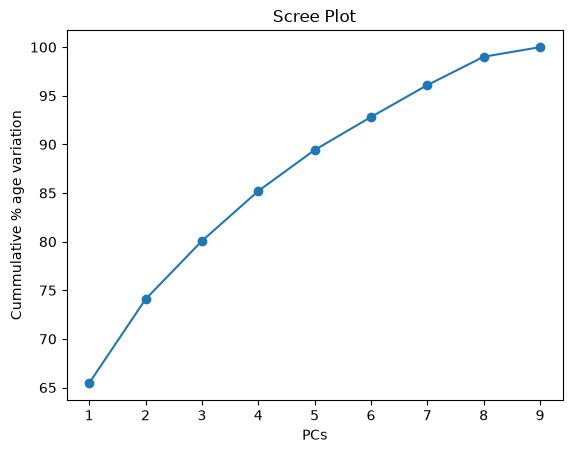

In [72]:
plt.scatter(range(1,10),np.cumsum(pca.explained_variance_ratio_*100))
plt.plot(range(1,10),np.cumsum(pca.explained_variance_ratio_*100))
plt.title("Scree Plot")
plt.xlabel("PCs")
plt.ylabel("Cummulative % age variation")
plt.show()

In [73]:
pc['Class'] = y

<Axes: xlabel='pca0', ylabel='pca1'>

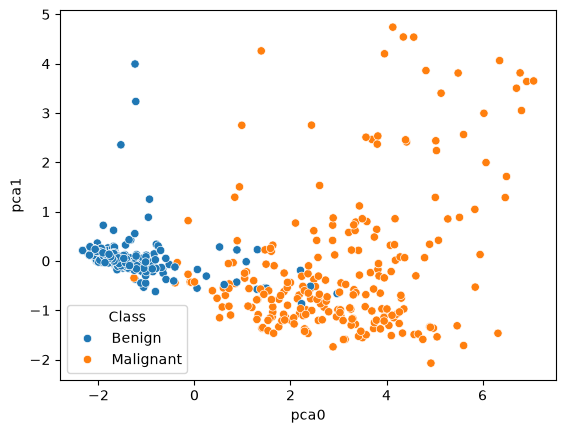

In [74]:
sns.scatterplot(data = pc , x='pca0',y='pca1',hue = 'Class')

## SVM

In [75]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [79]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)
svm = SVC(kernel='linear')
svm.fit(X_train,y_train)
y_pred = svm.predict(X_test)
f1_score(y_test,y_pred,pos_label='Malignant')


0.9324324324324325

In [78]:
prcomp = PCA(n_components=2).set_output(transform = 'pandas')
pipe = Pipeline([('STS',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")  #The F1 score is the harmonic mean of Precision and Recall

0.9395973154362416

In [80]:
prcomp = PCA(n_components=3).set_output(transform = 'pandas')
pipe = Pipeline([('STS',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant") 

0.9395973154362416

In [81]:
prcomp = PCA(n_components=4).set_output(transform = 'pandas')
pipe = Pipeline([('STS',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant") 

0.9530201342281879

In [82]:
prcomp = PCA(n_components=5).set_output(transform = 'pandas')
pipe = Pipeline([('STS',scaler),('PCA',prcomp),('SVM',svm)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant") 

0.9530201342281879